Cargamos la ROI generada en el Módulo 1 (en gris y en color). El video se usará posteriormente.

In [48]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from skimage.feature import graycomatrix, graycoprops

VIDEO_PATH = "../data/raw/Registro A_2.MOV"
ROI_PATH = "../data/reference/roi_A_gray.png"
ROI_RGB_PATH = "../data/reference/roi_A_rgb.png"

roi_gray = cv2.imread(ROI_PATH, cv2.IMREAD_GRAYSCALE)
roi_bgr = cv2.imread(ROI_RGB_PATH)

if roi_gray is None:
    raise RuntimeError(f"No se pudo cargar la ROI: {ROI_PATH}")
if roi_bgr is None:
    raise RuntimeError(f"No se pudo cargar la ROI: {ROI_RGB_PATH}")

roi_rgb = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2RGB)

print("ROI gris:", roi_gray.shape)
print("ROI RGB:", roi_rgb.shape)

ROI gris: (130, 320)
ROI RGB: (130, 320, 3)


Se utilizará la ROI cuantizada a 32 niveles (5 bits por canal). Esto será útil para que la GLCM sea mucho más chica y que sus estadísticas sean más estables con pocos píxeles.

In [49]:
NIVELES = 32                    # Puedo cambiar niveles para ver que pasa después si lo paso a 64
paso = 256 // NIVELES          

# Cuantización
roi_cuant = (roi_rgb // paso).astype(np.uint8)
gray_cuant = (roi_gray // paso).astype(np.uint8)

Segmentación de la pupila
Usamos la segmentación por Watershed del módulo 2, ya que fue la que mejor delimitó la pupila. Además, sumamos un cierre morfológico, que según la última tabla del mismo módulo fue de las operaciones que menos modificó la máscara.

A partir de la máscara extraemos el contorno externo de la pupila. Hacemos una función con la segmentación para poder reutilizarla en el video frame a frame.

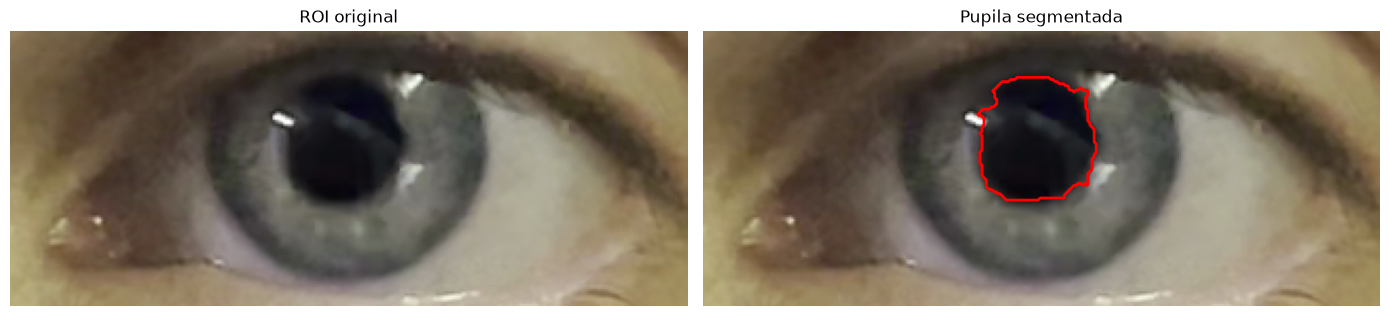

In [50]:
center_x, center_y = 155, 50

def segmentar_pupila(gris, cx=center_x, cy=center_y):
    """Segmenta la pupila con Watershed. Devuelve la máscara y su contorno externo"""
    # Hago el contraste + suavizado, tal como se hizo en el módulo 2
    contraste = np.clip(gris.astype(np.float32) * 1.5, 0, 255).astype(np.uint8)
    suavizada = cv2.GaussianBlur(contraste, (5, 5), 0)

    # Marcadores: 1 = pupila segura, 2 = fondo seguro (fuera de la elipse)
    marcadores = np.zeros(gris.shape, dtype=np.int32)
    cv2.circle(marcadores, (int(cx), int(cy)), 20, 1, -1)
    zona = np.zeros(gris.shape, dtype=np.uint8)
    cv2.ellipse(zona, (int(cx), int(cy)), (60, 55), 0, 0, 360, 1, -1)
    marcadores[zona == 0] = 2

    ws = cv2.watershed(cv2.cvtColor(suavizada, cv2.COLOR_GRAY2BGR), marcadores)
    mascara = (ws == 1).astype(np.uint8) * 255

    # Cierre morfológico con kernel elíptico de 5x5
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, kernel)

    # Contorno externo de la máscara
    contornos, _ = cv2.findContours(mascara.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    contorno = max(contornos, key=cv2.contourArea) if contornos else None
    return mascara, contorno

mask_pupila, contorno = segmentar_pupila(roi_gray)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(roi_rgb)
plt.title("ROI original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(roi_rgb)
plt.contour(mask_pupila > 0, colors="r", linewidths=2)
plt.title("Pupila segmentada")
plt.axis("off")

plt.tight_layout()
plt.show()

A continuación se calculará el área, que representa la cantidad de píxeles de la máscara, el perímetro, que es la longitud del borde de la región, las coordenadas del centroide, la circularidad y la excentricidad.

In [51]:
def descriptores_morfometricos(contorno):
    """Área, perímetro, centroide, circularidad y excentricidad de una máscara binaria."""
    area = cv2.contourArea(contorno)
    perimetro = cv2.arcLength(contorno, True)

    # Centroide a partir de los momentos del contorno
    m = cv2.moments(contorno)
    xc = m["m10"] / m["m00"]
    yc = m["m01"] / m["m00"]

    # Elipse que mejor se ajusta al contorno: de acá salen los ejes y la excentricidad
    elipse = cv2.fitEllipse(contorno)
    (_, _), (d1, d2), angulo = elipse
    eje_mayor, eje_menor = max(d1, d2), min(d1, d2)

    circularidad = 4 * np.pi * area / perimetro**2
    excentricidad = np.sqrt(1 - (eje_menor / eje_mayor) ** 2)

    return {
        "Área (px²)": area,
        "Perímetro (px)": perimetro,
        "Centroide X_c (px)": xc,
        "Centroide Y_c (px)": yc,
        "Circularidad": circularidad,
        "Excentricidad": excentricidad,
        "Eje mayor (px)": eje_mayor,
        "Eje menor (px)": eje_menor,
    }, elipse


desc, elipse = descriptores_morfometricos(contorno)

tabla_morfo = pd.DataFrame(desc, index=["Pupila (frame de referencia)"]).T
display(tabla_morfo.round(4))

,Pupila (frame de referencia)
Área (px²),2543.5000
Perímetro (px),210.6102
Centroide X_c (px),157.2433
Centroide Y_c (px),51.0816
Circularidad,0.7206
Excentricidad,0.3987
Eje mayor (px),60.1142
Eje menor (px),55.1307


In [ ]:
# # Verificación: el área del contorno vs. contar los píxeles de la máscara, y el centroide vs. el centro de la elipse
# area_pixeles = cv2.countNonZero(mask_pupila)
# (cx_el, cy_el), _, _ = elipse

# print(f"Área del contorno:         {desc['Área (px²)']:.0f}")
# print(f"Píxeles de la máscara:     {area_pixeles}")
# print(f"Centroide (momentos):      ({desc['Centroide X_c (px)']:.1f}, {desc['Centroide Y_c (px)']:.1f})")
# print(f"Centro de la elipse:       ({cx_el:.1f}, {cy_el:.1f})")
# print(f"Centro de entrada:         ({center_x}, {center_y})")

Área del contorno:         2544
Píxeles de la máscara:     2638
Centroide (momentos):      (157.2, 51.1)
Centro de la elipse:       (157.4, 51.1)
Centro de entrada:         (155, 50)


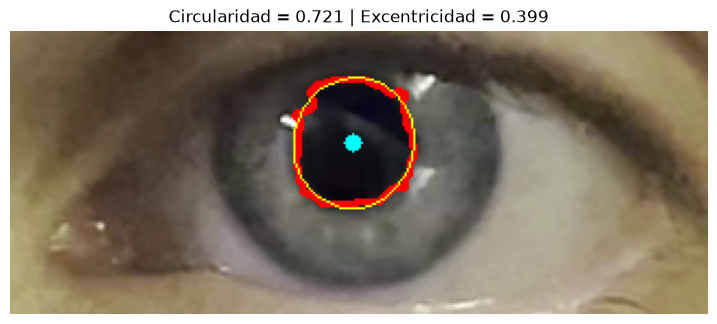

In [52]:
# Visualización: contorno, centroide y elipse ajustada
img = roi_rgb.copy()
cv2.drawContours(img, [contorno], -1, (255, 0, 0), 2)
cv2.ellipse(img, elipse, (255, 255, 0), 1)
cv2.circle(img, (int(round(desc["Centroide X_c (px)"])), int(round(desc["Centroide Y_c (px)"]))), 4, (0, 255, 255), -1)

plt.figure(figsize=(9, 5))
plt.imshow(img)
plt.title(f"Circularidad = {desc['Circularidad']:.3f} | Excentricidad = {desc['Excentricidad']:.3f}")
plt.axis("off")
plt.show()

Observando los resultados, se observa que el centroide de la pupila segmentada está en (157.2, 51.1), mientras que el centro asignado para aplicar Watershed se colocó en (155, 50), por lo que hay solo una leve diferencia entre estos dos centros.

La circularidad obtenida no es tan cercana a 1 por los bordes irregulares de la segmentación, que igualmente es adecuada para el análisis ya que, como se observa, rodea correctamente la pupila.

Más alla de que la circularidad no fue tan cercana a 1, el tamaño de los ejes de la elipse ajustada indican que la pupila sigue una forma aproximadamente circular.

A continuación, se calculará la media, desvío estándar, entropía y asimetría sobre la ROI de la pupila y el iris en los 3 canales de colores (RGB) de forma independiente.

Para analizar la textura del iris lo segmentamos también por Watershed, con tres marcadores: iris seguro (un anillo cercano a la pupila), pupila segura y fondo seguro (todo lo que queda fuera de una elipse grande). Esta segmentación se usa solo para el análisis de textura del frame de referencia, por lo que no se aplican correcciones adicionales, y se verifica visualmente que sea aproximadamente correcta.

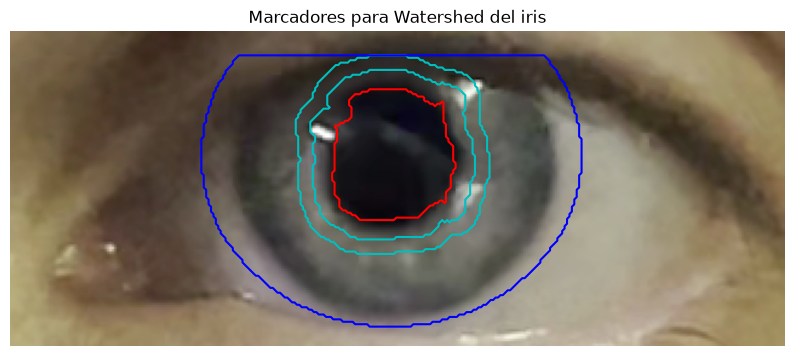

In [53]:
# Parámetros de los marcadores
ANILLO_INT, ANILLO_EXT = 6, 12   # iris "seguro": anillo entre estas dos distancias (px) al borde de la pupila
FONDO_RX, FONDO_RY = 78, 70      # semiejes (px) de la elipse: fuera de ella es fondo seguro
Y_PARPADO = 10                   # filas de arriba de la ROI que se consideran fondo (pestañas / párpado)

cx, cy = int(round(desc["Centroide X_c (px)"])), int(round(desc["Centroide Y_c (px)"]))

def kernel_elipse(r):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))

marcadores_iris = np.zeros(roi_gray.shape, dtype=np.int32)

# 2 = fondo seguro: fuera de la elipse y en la franja superior
zona = np.zeros(roi_gray.shape, dtype=np.uint8)
cv2.ellipse(zona, (cx, cy), (FONDO_RX, FONDO_RY), 0, 0, 360, 1, -1)
marcadores_iris[zona == 0] = 2
marcadores_iris[:Y_PARPADO, :] = 2

# 1 = iris seguro: anillo cercano a la pupila
anillo_semilla = cv2.subtract(cv2.dilate(mask_pupila, kernel_elipse(ANILLO_EXT)),
                              cv2.dilate(mask_pupila, kernel_elipse(ANILLO_INT)))
marcadores_iris[anillo_semilla > 0] = 1

# 3 = pupila segura (para que el iris no la invada)
marcadores_iris[cv2.erode(mask_pupila, kernel_elipse(2)) > 0] = 3

plt.figure(figsize=(10, 5))
plt.imshow(roi_rgb)
plt.contour(marcadores_iris == 1, colors="c", linewidths=1.5)
plt.contour(marcadores_iris == 2, colors="b", linewidths=1.5)
plt.contour(marcadores_iris == 3, colors="r", linewidths=1.5)
plt.title("Marcadores para Watershed del iris")
plt.axis("off")
plt.show()

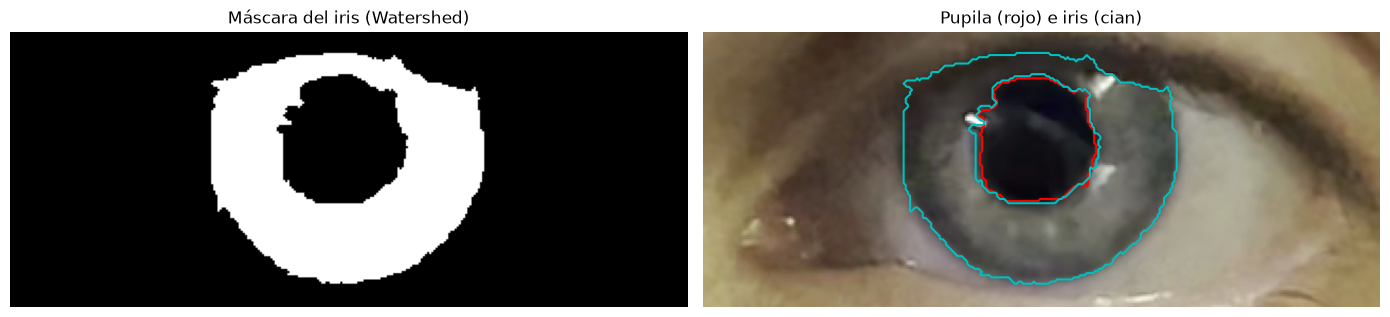

Píxeles de la pupila: 2638
Píxeles del iris:     8393


In [54]:
# Watershed sobre la ROI suavizada
roi_suavizada_iris = cv2.GaussianBlur(roi_gray, (5, 5), 0)
ws_iris = cv2.watershed(cv2.cvtColor(roi_suavizada_iris, cv2.COLOR_GRAY2BGR), marcadores_iris.copy())
mask_iris = (ws_iris == 1).astype(np.uint8) * 255

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(mask_iris, cmap="gray")
plt.title("Máscara del iris (Watershed)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(roi_rgb)
plt.contour(mask_pupila > 0, colors="r", linewidths=1.5)
plt.contour(mask_iris > 0, colors="c", linewidths=1.5)
plt.title("Pupila (rojo) e iris (cian)")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Píxeles de la pupila:", cv2.countNonZero(mask_pupila))
print("Píxeles del iris:    ", cv2.countNonZero(mask_iris))

Para evitar errores en los cálculos estadísticos, se deben excluir los reflejos brillantes que se observan en el iris.

Iris: mediana = 85 | percentil 99 = 187 | máximo = 255


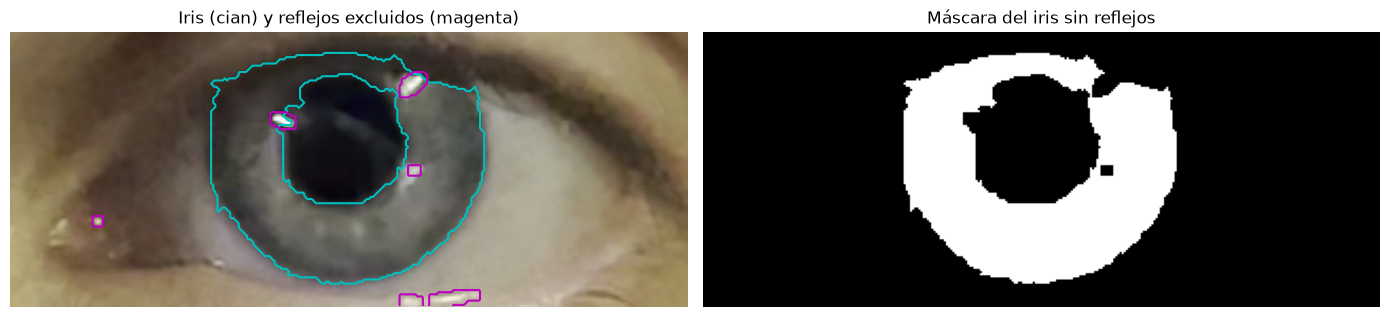

Píxeles del iris antes:   8393
Píxeles del iris después: 8209


In [55]:
UMBRAL_BRILLO = 205   # nivel de gris a partir del cual un píxel se considera reflejo

# Para elegir el umbral: cómo son los valores del iris
valores_iris = roi_gray[mask_iris > 0]
print("Iris: mediana =", int(np.median(valores_iris)), "| percentil 99 =", int(np.percentile(valores_iris, 99)), "| máximo =", int(valores_iris.max()))

# Reflejos: píxeles muy claros, con un pequeño margen alrededor
_, mask_brillo = cv2.threshold(roi_gray, UMBRAL_BRILLO, 255, cv2.THRESH_BINARY)
mask_brillo = cv2.dilate(mask_brillo, np.ones((5, 5), np.uint8))

# Iris sin reflejos
mask_iris_sin_brillo = cv2.bitwise_and(mask_iris, cv2.bitwise_not(mask_brillo))

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(roi_rgb)
plt.contour(mask_iris > 0, colors="c", linewidths=1.5)
plt.contour(mask_brillo > 0, colors="m", linewidths=1.5)
plt.title("Iris (cian) y reflejos excluidos (magenta)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask_iris_sin_brillo, cmap="gray")
plt.title("Máscara del iris sin reflejos")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Píxeles del iris antes:  ", cv2.countNonZero(mask_iris))
print("Píxeles del iris después:", cv2.countNonZero(mask_iris_sin_brillo))

La entropía mide la proporción de píxeles de la región en cada nivel de gris, mientras que la asimetría es positiva si la distribución tiene una cola hacia valores altos y negativa si la tiene hacia valores bajos.

In [56]:
def estadisticas_primer_orden(img_cuant, mascara, niveles=NIVELES):
    """Media, desvío, entropía y asimetría de cada canal (R, G, B), solo dentro de la máscara."""
    medias, desvios = cv2.meanStdDev(img_cuant, mask=mascara)

    filas = {}
    for i, canal in enumerate("RGB"):
        # Entropía (en bits) a partir del histograma de los niveles cuantizados
        hist = cv2.calcHist([img_cuant], [i], mascara, [niveles], [0, niveles]).ravel()
        p = hist / hist.sum()
        p = p[p > 0]
        entropia = -np.sum(p * np.log2(p))

        # Asimetría (skewness) de los valores de los píxeles dentro de la máscara
        valores = img_cuant[:, :, i][mascara > 0]
        asimetria = pd.Series(valores).skew()

        filas[canal] = {
            "Media": medias[i, 0],
            "Desvío": desvios[i, 0],
            "Entropía (bits)": entropia,
            "Asimetría": asimetria,
        }
    return pd.DataFrame(filas).T


stats_pupila = estadisticas_primer_orden(roi_cuant, mask_pupila)
stats_iris = estadisticas_primer_orden(roi_cuant, mask_iris_sin_brillo)

print("PUPILA")
display(stats_pupila.round(3))
print("IRIS")
display(stats_iris.round(3))

PUPILA


,Media,Desvío,Entropía (bits),Asimetría
R,2.528,1.740,2.430,2.687
G,2.466,1.808,2.526,2.314
B,3.162,1.593,2.348,2.689


IRIS


,Media,Desvío,Entropía (bits),Asimetría
R,10.065,3.129,3.567,0.088
G,9.877,3.280,3.608,-0.037
B,9.197,3.104,3.568,-0.017


La pupila es más oscura y uniforme que el iris: sus medias están entre 2.5 y 3.2, contra cerca de 10 en el iris, y tiene menor desvío y entropía, lo cual es lo esperable, ya que el estroma iridiano presenta más variación de intensidad que la pupila.

La asimetría de la pupila es positiva y alta (2.3 a 2.7), probablemente por el reflejo del flash, que no se excluyó en esa región. En el iris es casi nula, por lo que la distribución de intensidades es aproximadamente simétrica.

Entre canales las diferencias son pequeñas. En la pupila el canal B es algo más claro, y en el iris los tres canales tienen medias, desvíos y entropías muy parecidos.

La GLCM cuenta con qué frecuencia aparece un nivel de gris `i` junto a un nivel `j` a una distancia y dirección dadas. Así describe la relación espacial entre píxeles. Los atributos se calculan por canal y se promedian sobre los 4 ángulos.

In [57]:
DISTANCIAS = [1]
ANGULOS = [0, np.pi/4, np.pi/2, 3*np.pi/4]

def glcm_mascara(canal, mascara, niveles=NIVELES):
    img = canal.copy()
    img[mascara == 0] = niveles                      # nivel extra = "fuera de la región"
    glcm = graycomatrix(img, distances=DISTANCIAS, angles=ANGULOS,
                        levels=niveles + 1, symmetric=True, normed=False)
    glcm = glcm[:niveles, :niveles].astype(float)    # se descarta el nivel de fondo
    glcm /= glcm.sum(axis=(0, 1), keepdims=True)     # se renormaliza
    return glcm

def atributos_glcm(glcm):
    props = {"Contraste": "contrast", "Homogeneidad": "homogeneity",
             "Energía": "energy", "Correlación": "correlation"}
    return {nombre: graycoprops(glcm, p).mean() for nombre, p in props.items()}

In [58]:
glcms = {}
filas_pupila, filas_iris = {}, {}

for idx, canal in enumerate("RGB"):
    img_canal = roi_cuant[:, :, idx]
    glcms[("Pupila", canal)] = glcm_mascara(img_canal, mask_pupila)
    glcms[("Iris", canal)] = glcm_mascara(img_canal, mask_iris_sin_brillo)
    filas_pupila[canal] = atributos_glcm(glcms[("Pupila", canal)])
    filas_iris[canal] = atributos_glcm(glcms[("Iris", canal)])

glcm_pupila = pd.DataFrame(filas_pupila).T
glcm_iris = pd.DataFrame(filas_iris).T

print("GLCM – Pupila")
display(glcm_pupila.round(4))
print("GLCM – Iris")
display(glcm_iris.round(4))

GLCM – Pupila


,Contraste,Homogeneidad,Energía,Correlación
R,0.5549,0.8475,0.3920,0.8966
G,0.5614,0.8448,0.3861,0.9049
B,0.5096,0.8596,0.4192,0.8896


GLCM – Iris


,Contraste,Homogeneidad,Energía,Correlación
R,0.5632,0.8062,0.2094,0.9708
G,0.5485,0.8092,0.2087,0.9741
B,0.5548,0.8070,0.2127,0.9707


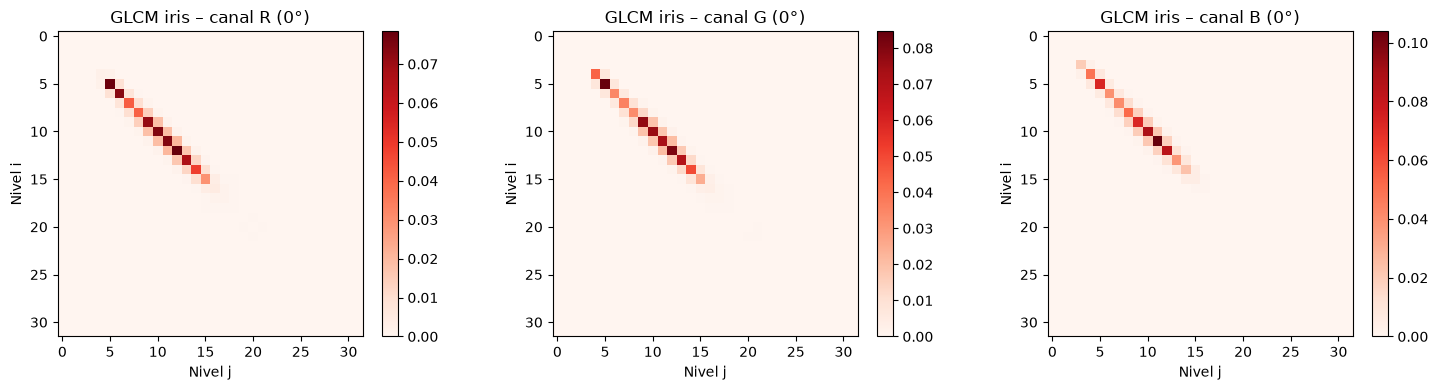

In [59]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, canal in zip(axs, "RGB"):
    im = ax.imshow(glcms[("Iris", canal)][:, :, 0, 0], cmap="Reds")
    ax.set_title(f"GLCM iris – canal {canal} (0°)")
    ax.set_xlabel("Nivel j"); ax.set_ylabel("Nivel i")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

En el iris, los tres canales dan valores de GLCM muy parecidos. Las GLCM de la figura se concentran sobre la diagonal, con niveles de gris vecinos, lo que indica una textura suave, con variaciones graduales entre píxeles. Esto coincide con la correlación y homogeneidad alta.

Entre canales, R muestra mayor contraste (0.563) y menor homogeneidad (0.806). G tiene la energía más baja (0.2087) y la correlación más alta (0.974), y B tiene la mayor energía (0.213), es decir, es el más uniforme. Las diferencias son pcas, por lo que ningún canal aporta una riqueza textural claramente mayor. Sin embargo, podemos decir que R es el más informativo, debido al mayor contraste y menor homogeneidad.

La pupila es más homogénea y tiene mayor energía que el iris, como se espera de una región más uniforme y oscura. Su contraste es similar al del iris, probablemente por los bordes y el brillo que quedaron dentro de la máscara.